# 01 — EDA Dataset Daun Cabai

Tujuan notebook ini:
1. Memastikan dataset terbaca dengan benar (jumlah foto per kelas, file rusak).
2. Melihat contoh foto tiap kelas dan ukuran gambarnya.
3. Menemukan **duplikat** (persis sama atau hampir sama) supaya tidak bocor antara data train dan test.
4. Membuat pembagian **train / val / test (70/15/15)** yang disimpan ke `splits.csv` untuk notebook training.

Bisa dijalankan di **laptop (VS Code)** atau di **Colab**; sel konfigurasi di bawah mendeteksinya otomatis.
Semua grafik dan tabel tersimpan di folder `reports/eda/`, siap dipakai di slide presentasi.

## 1. Konfigurasi
Ubah nilai di sel ini saja bila lokasi dataset Anda berbeda.

In [15]:
import sys, os, zipfile
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# --- Laptop (VS Code) ---
# Notebook ada di folder notebooks/, jadi root project = satu folder di atasnya
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
LOCAL_DATA_DIR = PROJECT_ROOT / "data" / "raw" / "chilli_leaf"

# --- Colab ---
DRIVE_ZIP = "/content/drive/MyDrive/dokter-tani/chilli_leaf.zip"   # zip dataset di Google Drive
DRIVE_OUT = "/content/drive/MyDrive/dokter-tani/reports"            # hasil disimpan ke Drive agar tidak hilang

SEED = 42
SPLIT = (0.70, 0.15, 0.15)   # train / val / test

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = Path("/content/data/raw/chilli_leaf")
    if not DATA_DIR.exists():
        print("Mengekstrak zip dari Drive ke runtime (sekali per sesi)...")
        with zipfile.ZipFile(DRIVE_ZIP) as z:
            z.extractall(DATA_DIR)
    OUT_DIR = Path(DRIVE_OUT) / "eda"
else:
    DATA_DIR = LOCAL_DATA_DIR
    OUT_DIR = PROJECT_ROOT / "reports" / "eda"

OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Berjalan di :", "Colab" if IN_COLAB else "laptop")
print("Dataset     :", DATA_DIR, "| ada:", DATA_DIR.exists())
print("Output      :", OUT_DIR)
assert DATA_DIR.exists(), f"Folder dataset tidak ditemukan: {DATA_DIR}. Lihat data/README.md"

Berjalan di : laptop
Dataset     : c:\laragon\www\final-project\dokter-tani\data\raw\chilli_leaf | ada: True
Output      : c:\laragon\www\final-project\dokter-tani\reports\eda


In [16]:
# Di Colab, imagehash belum terpasang
try:
    import imagehash
except ImportError:
    %pip install -q imagehash
    import imagehash

import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split

pd.set_option("display.max_colwidth", 80)

# Gaya grafik: tenang, satu warna, grid samar
INK, MUTED, GRID, BAR = "#18241B", "#5B6660", "#E3E6DC", "#2E6B3A"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
})

## 2. Memindai semua file gambar
Nama kelas = nama folder tempat foto berada. Setiap file dibuka untuk mengecek apakah rusak, lalu dihitung *hash*-nya untuk mencari duplikat.

In [17]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

files = [p for p in DATA_DIR.rglob("*")
         if p.is_file() and p.suffix.lower() in IMG_EXT
         and "__MACOSX" not in p.parts and not p.name.startswith(".")]
print(f"Ditemukan {len(files):,} file gambar")

rows = []
for p in tqdm(files, desc="Memindai"):
    r = {"path": str(p), "rel_path": str(p.relative_to(DATA_DIR)), "label": p.parent.name,
         "bytes": p.stat().st_size, "width": None, "height": None, "mode": None,
         "corrupt": False, "md5": None, "phash": None, "brightness": None, "green_ratio": None}
    try:
        data = p.read_bytes()
        r["md5"] = hashlib.md5(data).hexdigest()
        with Image.open(p) as im:
            im.verify()                         # cek struktur file
        with Image.open(p) as im:
            im = ImageOps.exif_transpose(im)    # ikuti orientasi foto HP
            r["width"], r["height"], r["mode"] = im.width, im.height, im.mode
            rgb = im.convert("RGB")
            r["phash"] = str(imagehash.phash(rgb))
            small = np.asarray(rgb.resize((64, 64)), dtype=np.float32)
            r["brightness"] = float(small.mean())
            r["green_ratio"] = float(small[..., 1].mean() / (small.sum(axis=2).mean() + 1e-6))
    except Exception as e:
        r["corrupt"] = True
        r["error"] = repr(e)[:120]
    rows.append(r)

df = pd.DataFrame(rows)
df.to_csv(OUT_DIR / "files_index.csv", index=False)
df.head()

Ditemukan 8,817 file gambar


Memindai: 100%|██████████| 8817/8817 [03:43<00:00, 39.40it/s] 


,path,rel_path,label,bytes,width,height,mode,corrupt,md5,phash,brightness,green_ratio
0,c:\laragon\www\final-project\dokter-tani\data\raw\chilli_leaf\Chilli Leaf Di...,Chilli Leaf Disease Image Dataset for Classificati\Nutrition_Deficiency\Nutr...,Nutrition_Deficiency,1324803,4000,3000,RGB,False,bbbcab6497f717882e7b85f485f5f8e7,b6c0c93d2ef0930f,145.850266,0.340180
1,c:\laragon\www\final-project\dokter-tani\data\raw\chilli_leaf\Chilli Leaf Di...,Chilli Leaf Disease Image Dataset for Classificati\Nutrition_Deficiency\Nutr...,Nutrition_Deficiency,67559,256,256,RGBA,False,8da43261e7c11b3ab8a9fa0bb944e09b,bf60d097cb1a6c0d,207.322342,0.356401
2,c:\laragon\www\final-project\dokter-tani\data\raw\chilli_leaf\Chilli Leaf Di...,Chilli Leaf Disease Image Dataset for Classificati\Nutrition_Deficiency\Nutr...,Nutrition_Deficiency,986292,2398,4900,RGB,False,2d120e3b59cd204b4b54c5ef32957da7,a51b96f0d8d9894b,175.171143,0.348250
3,c:\laragon\www\final-project\dokter-tani\data\raw\chilli_leaf\Chilli Leaf Di...,Chilli Leaf Disease Image Dataset for Classificati\Nutrition_Deficiency\Nutr...,Nutrition_Deficiency,61524,256,256,RGBA,False,7f733ecec727e645a1c174af32a1a562,e431c3e392e6939c,216.979172,0.352331
4,c:\laragon\www\final-project\dokter-tani\data\raw\chilli_leaf\Chilli Leaf Di...,Chilli Leaf Disease Image Dataset for Classificati\Nutrition_Deficiency\Nutr...,Nutrition_Deficiency,70546,256,256,RGBA,False,b371cd8b982f6ffc4e0182f3a97624e8,bfe0c013cf1cf21c,186.304764,0.359761


## 3. Jumlah foto per kelas
Kelas yang jauh lebih sedikit perlu perhatian saat training (*weighted loss* atau *oversampling*).

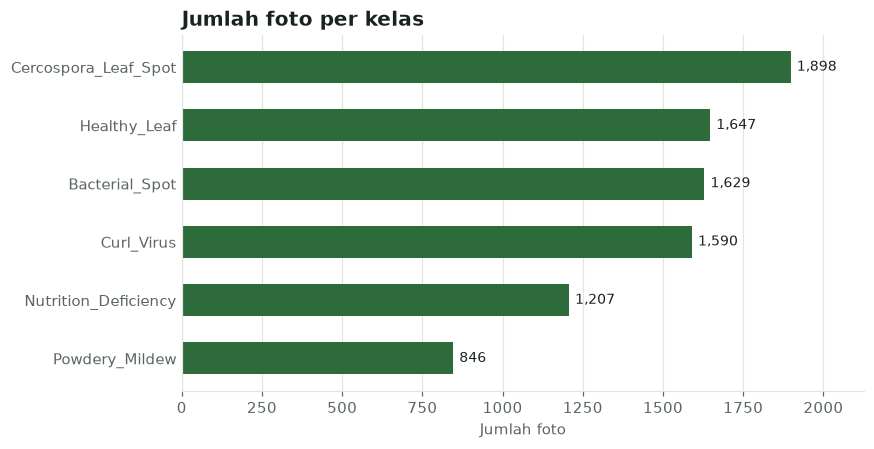

Total foto valid: 8,817 | 6 kelas | rasio terbanyak/tersedikit: 2.2x


,jumlah,persen
label,,
Cercospora_Leaf_Spot,1898,21.5
Healthy_Leaf,1647,18.7
Bacterial_Spot,1629,18.5
Curl_Virus,1590,18.0
Nutrition_Deficiency,1207,13.7
Powdery_Mildew,846,9.6


In [18]:
ok = df[~df["corrupt"]]
counts = ok["label"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(8, 0.5 * len(counts) + 1.2))
bars = ax.barh(counts.index, counts.values, color=BAR, height=0.55)
ax.bar_label(bars, labels=[f"{v:,}" for v in counts.values], padding=4, color=INK, fontsize=9)
ax.set_title("Jumlah foto per kelas")
ax.set_xlabel("Jumlah foto")
ax.xaxis.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.set_xlim(0, counts.max() * 1.12)
fig.savefig(OUT_DIR / "01_jumlah_per_kelas.png"); plt.show()

ratio = counts.max() / counts.min()
summary = pd.DataFrame({"jumlah": counts[::-1], "persen": (counts[::-1] / counts.sum() * 100).round(1)})
print(f"Total foto valid: {counts.sum():,} | {len(counts)} kelas | rasio terbanyak/tersedikit: {ratio:.1f}x")
summary

## 4. Contoh foto tiap kelas
Perhatikan: kelas mana yang terlihat mirip? Apakah latar belakangnya berbeda-beda (bisa jadi *shortcut* bagi model)?

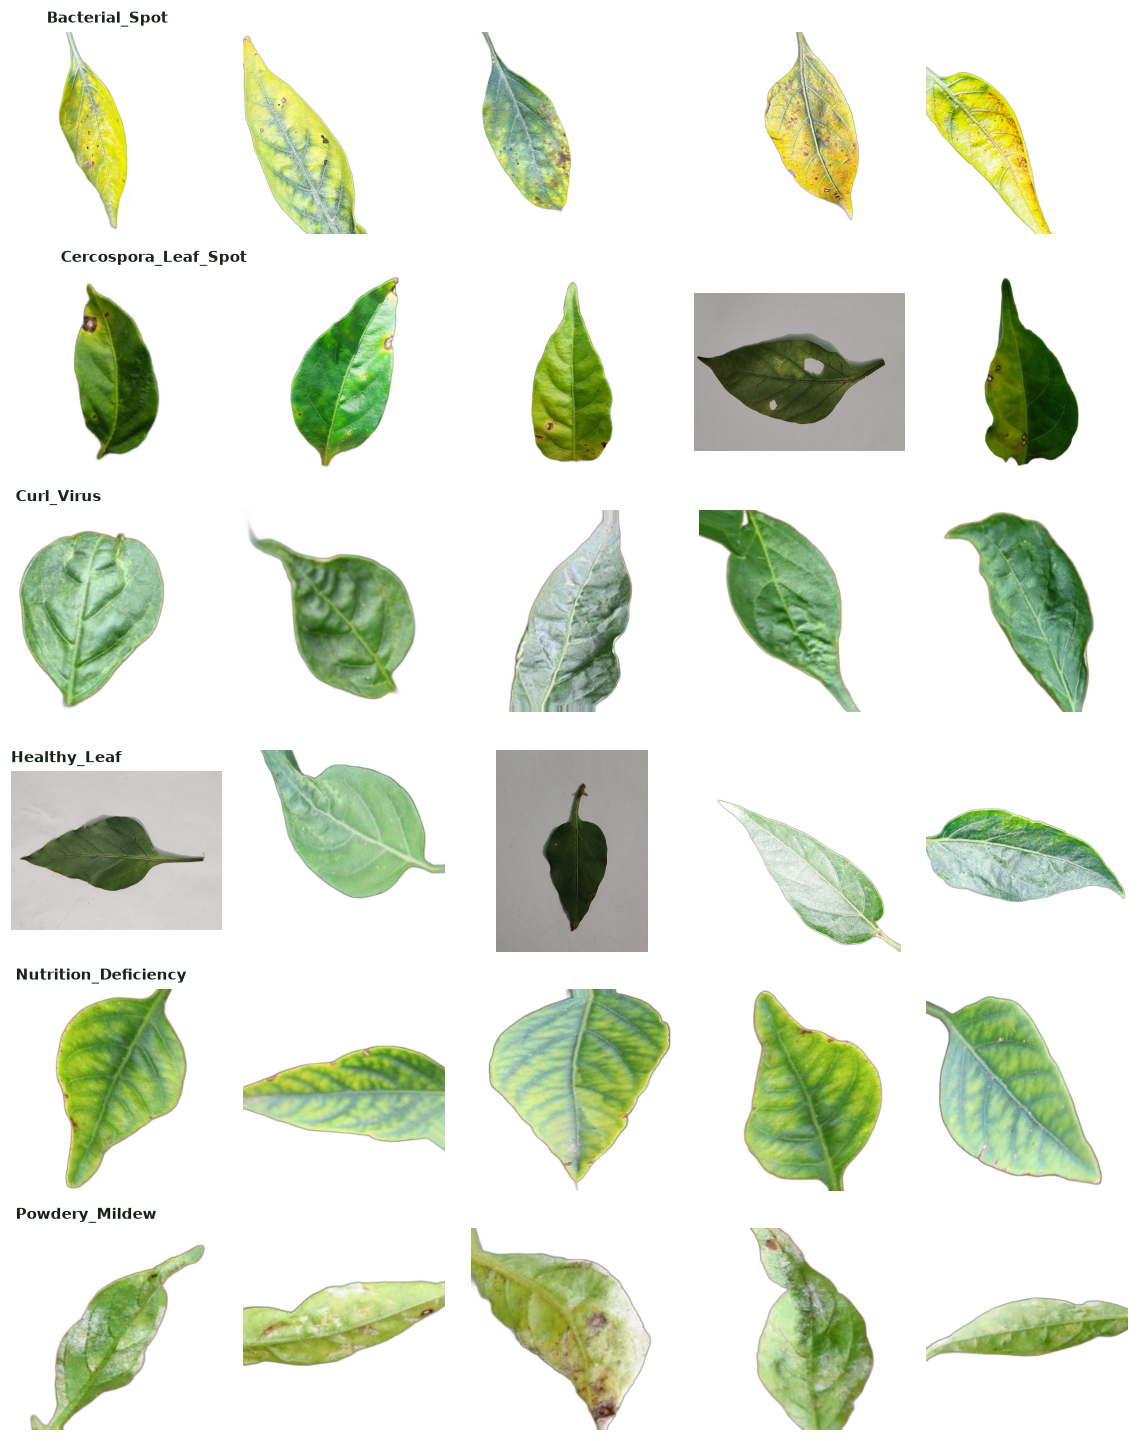

In [19]:
N_PER_CLASS = 5
labels = sorted(ok["label"].unique())
fig, axes = plt.subplots(len(labels), N_PER_CLASS, figsize=(2.1 * N_PER_CLASS, 2.2 * len(labels)))
axes = np.atleast_2d(axes)
for i, lab in enumerate(labels):
    sample = ok[ok["label"] == lab].sample(min(N_PER_CLASS, (ok["label"] == lab).sum()), random_state=SEED)
    for j in range(N_PER_CLASS):
        ax = axes[i, j]; ax.axis("off")
        if j < len(sample):
            with Image.open(sample.iloc[j]["path"]) as im:
                ax.imshow(ImageOps.exif_transpose(im).convert("RGB"))
        if j == 0:
            ax.set_title(lab, loc="left", fontsize=10, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(OUT_DIR / "02_contoh_per_kelas.png"); plt.show()

## 5. Ukuran gambar, kecerahan, dan warna
Model akan memakai ukuran 224×224, jadi yang penting: apakah ada gambar yang sangat kecil atau sangat lonjong? Kecerahan dan proporsi hijau per kelas menunjukkan apakah ada kelas yang difoto dalam kondisi berbeda.

In [20]:
size_tbl = (ok.assign(ukuran=ok["width"].astype(int).astype(str) + "×" + ok["height"].astype(int).astype(str))
              ["ukuran"].value_counts().head(10).rename("jumlah").to_frame())
print("10 ukuran gambar paling umum:")
display(size_tbl)

small = ok[(ok["width"] < 224) | (ok["height"] < 224)]
aspect = ok["width"] / ok["height"]
print(f"Gambar lebih kecil dari 224 px: {len(small)}")
print(f"Gambar sangat lonjong (rasio > 2 atau < 0.5): {int(((aspect > 2) | (aspect < 0.5)).sum())}")

color_tbl = (ok.groupby("label")[["brightness", "green_ratio"]].agg(["mean", "std"]).round(3))
color_tbl.to_csv(OUT_DIR / "kecerahan_warna_per_kelas.csv")
color_tbl

10 ukuran gambar paling umum:


,jumlah
ukuran,
256×256,3577
1000×1000,2028
640×640,416
4000×3000,398
3000×4000,127
517×640,6
3048×4064,5
1314×1314,4
473×640,4


Gambar lebih kecil dari 224 px: 1
Gambar sangat lonjong (rasio > 2 atau < 0.5): 754


brightness         green_ratio       
                           mean     std        mean    std
label                                                     
Bacterial_Spot          217.476  25.444       0.350  0.014
Cercospora_Leaf_Spot    171.326  19.993       0.361  0.011
Curl_Virus              203.279  25.935       0.348  0.012
Healthy_Leaf            211.440  26.032       0.349  0.009
Nutrition_Deficiency    202.026  22.888       0.356  0.010
Powdery_Mildew          220.673  11.703       0.347  0.007

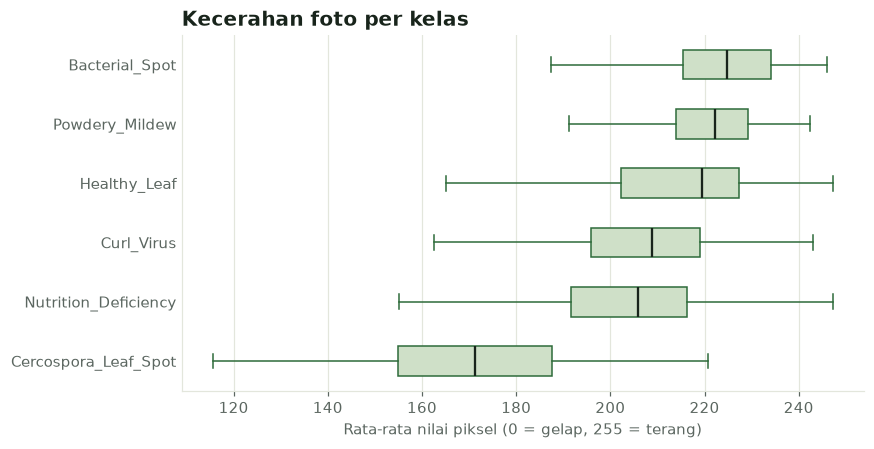

In [21]:
order = ok.groupby("label")["brightness"].median().sort_values().index
data = [ok.loc[ok["label"] == l, "brightness"].values for l in order]
fig, ax = plt.subplots(figsize=(8, 0.5 * len(order) + 1.2))
style = dict(widths=0.5, patch_artist=True, showfliers=False,
             medianprops=dict(color=INK, linewidth=1.5),
             boxprops=dict(facecolor="#CFE0C8", edgecolor=BAR, linewidth=1),
             whiskerprops=dict(color=BAR), capprops=dict(color=BAR))
try:
    ax.boxplot(data, orientation="horizontal", **style)   # matplotlib baru
except TypeError:
    ax.boxplot(data, vert=False, **style)                 # matplotlib lama (Colab)
ax.set_yticks(range(1, len(order) + 1), order)
ax.set_title("Kecerahan foto per kelas")
ax.set_xlabel("Rata-rata nilai piksel (0 = gelap, 255 = terang)")
ax.xaxis.grid(True, color=GRID, linewidth=0.8); ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
fig.savefig(OUT_DIR / "03_kecerahan_per_kelas.png"); plt.show()

## 6. File rusak

In [22]:
bad = df[df["corrupt"]]
print(f"File rusak: {len(bad)}")
bad[["rel_path", "label", "error"]] if len(bad) else None

File rusak: 0


## 7. Duplikat

- **Persis sama** (`md5` sama): file kembar. Simpan satu saja.
- **Hampir sama** (`phash` sama): foto yang sama tetapi di-resize, dikompres ulang, atau sedikit berbeda.
  Foto seperti ini **harus berada di split yang sama**. Kalau satu di train dan satu di test, akurasi test akan terlihat lebih bagus dari kenyataan (*data leakage*).
- **Konflik label**: foto yang sama muncul di dua kelas berbeda. Ini harus dicek manual.

In [23]:
exact_groups = ok.groupby("md5").filter(lambda g: len(g) > 1)
near_groups  = ok.groupby("phash").filter(lambda g: len(g) > 1)
conflict     = near_groups.groupby("phash").filter(lambda g: g["label"].nunique() > 1)

print(f"Duplikat persis : {len(exact_groups):,} file dalam {exact_groups['md5'].nunique():,} kelompok")
print(f"Hampir sama     : {len(near_groups):,} file dalam {near_groups['phash'].nunique():,} kelompok")
print(f"Konflik label   : {len(conflict):,} file dalam {conflict['phash'].nunique():,} kelompok")

near_groups.sort_values("phash")[["phash", "label", "rel_path"]].to_csv(OUT_DIR / "duplikat_hampir_sama.csv", index=False)
conflict.sort_values("phash")[["phash", "label", "rel_path"]].to_csv(OUT_DIR / "konflik_label.csv", index=False)
conflict.sort_values("phash")[["phash", "label", "rel_path"]].head(20)

Duplikat persis : 1,668 file dalam 787 kelompok
Hampir sama     : 2,272 file dalam 990 kelompok
Konflik label   : 0 file dalam 0 kelompok


,phash,label,rel_path


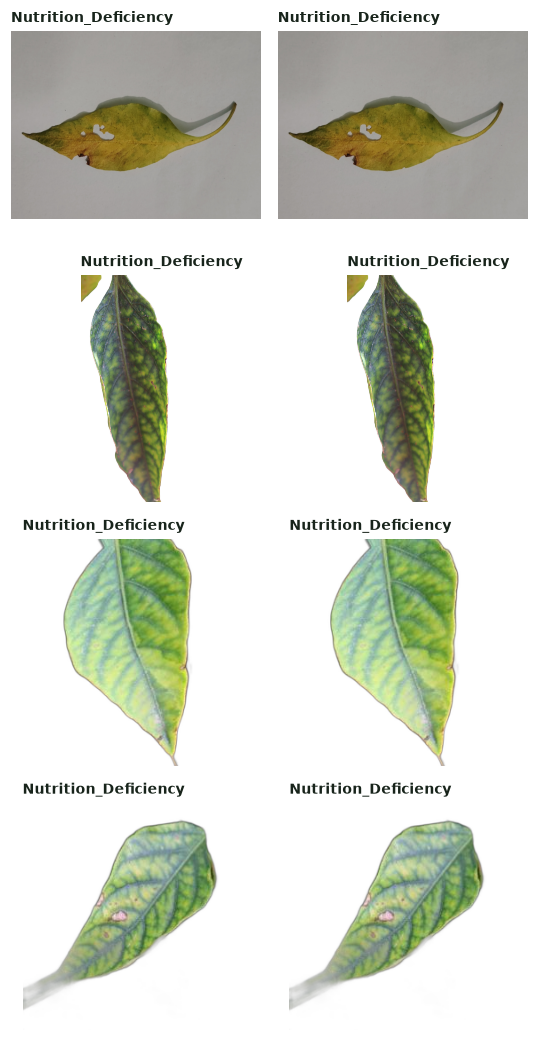

In [24]:
# Lihat beberapa contoh pasangan hampir sama, untuk memastikan memang duplikat
show = near_groups["phash"].drop_duplicates().head(4).tolist()
if show:
    fig, axes = plt.subplots(len(show), 2, figsize=(5, 2.4 * len(show)))
    axes = np.atleast_2d(axes)
    for i, h in enumerate(show):
        grp = near_groups[near_groups["phash"] == h].head(2)
        for j in range(2):
            ax = axes[i, j]; ax.axis("off")
            if j < len(grp):
                with Image.open(grp.iloc[j]["path"]) as im:
                    ax.imshow(ImageOps.exif_transpose(im).convert("RGB"))
                ax.set_title(f"{grp.iloc[j]['label']}", fontsize=9, color=INK, loc="left")
    fig.tight_layout(); fig.savefig(OUT_DIR / "04_contoh_duplikat.png"); plt.show()
else:
    print("Tidak ada foto yang hampir sama.")

## 8. Pembagian train / val / test

Aturan:
1. File rusak dibuang.
2. Duplikat persis: hanya satu yang disimpan.
3. Kelompok dengan konflik label dibuang (cek manual nanti di `konflik_label.csv`).
4. Foto yang hampir sama dikelompokkan, lalu **satu kelompok utuh** masuk ke satu split saja.
5. Pembagian *stratified* per kelas, dengan seed tetap supaya bisa diulang.

In [25]:
clean = ok.drop_duplicates("md5").copy()
clean = clean[~clean["phash"].isin(conflict["phash"])]
clean["group"] = clean["phash"]

groups = clean.groupby("group")["label"].first().reset_index()
train_val_p, test_p = 1 - SPLIT[2], SPLIT[2]
g_trainval, g_test = train_test_split(groups, test_size=test_p, stratify=groups["label"], random_state=SEED)
g_train, g_val = train_test_split(g_trainval, test_size=SPLIT[1] / train_val_p,
                                  stratify=g_trainval["label"], random_state=SEED)

split_of = {**{g: "train" for g in g_train["group"]},
            **{g: "val" for g in g_val["group"]},
            **{g: "test" for g in g_test["group"]}}
clean["split"] = clean["group"].map(split_of)

# Pemeriksaan kebocoran: setiap kelompok hanya boleh ada di satu split
assert clean.groupby("group")["split"].nunique().max() == 1, "Ada kelompok di lebih dari satu split!"

splits = clean[["rel_path", "label", "split", "group", "width", "height"]].astype({"width": int, "height": int})
SPLITS_OUT = Path(DRIVE_OUT).parent / "splits.csv" if IN_COLAB else PROJECT_ROOT / "data" / "splits.csv"
splits.to_csv(SPLITS_OUT, index=False)   # dibaca notebook 02–06

tbl = pd.crosstab(splits["label"], splits["split"])[["train", "val", "test"]]
tbl.loc["TOTAL"] = tbl.sum()
print(f"Dibuang: {len(df) - len(clean):,} file (rusak, duplikat persis, atau konflik label)")
tbl

Dibuang: 881 file (rusak, duplikat persis, atau konflik label)


split,train,val,test
label,,,
Bacterial_Spot,878,217,185
Cercospora_Leaf_Spot,1177,252,254
Curl_Virus,1110,237,235
Healthy_Leaf,1037,223,221
Nutrition_Deficiency,746,161,160
Powdery_Mildew,591,126,126
TOTAL,5539,1216,1181


## 9. Ringkasan untuk `CATATAN.md` dan slide

In [26]:
lines = [
    f"- Total file ditemukan: {len(df):,}",
    f"- File rusak: {int(df['corrupt'].sum())}",
    f"- Kelas: {len(counts)} ({', '.join(counts.index[::-1])})",
    f"- Kelas terbanyak: {counts.idxmax()} ({counts.max():,}); tersedikit: {counts.idxmin()} ({counts.min():,}); rasio {ratio:.1f}x",
    f"- Duplikat persis: {len(exact_groups):,} file; hampir sama: {len(near_groups):,} file; konflik label: {len(conflict):,} file",
    f"- Data bersih untuk training: {len(clean):,} foto → train {int((clean['split']=='train').sum()):,} / "
    f"val {int((clean['split']=='val').sum()):,} / test {int((clean['split']=='test').sum()):,}",
    f"- Ukuran paling umum: {size_tbl.index[0]}",
]
text = "\n".join(lines)
(OUT_DIR / "ringkasan_eda.md").write_text("# Ringkasan EDA\n\n" + text + "\n", encoding="utf-8")
print(text)
print(f"\nSemua hasil tersimpan di: {OUT_DIR}")

- Total file ditemukan: 8,817
- File rusak: 0
- Kelas: 6 (Cercospora_Leaf_Spot, Healthy_Leaf, Bacterial_Spot, Curl_Virus, Nutrition_Deficiency, Powdery_Mildew)
- Kelas terbanyak: Cercospora_Leaf_Spot (1,898); tersedikit: Powdery_Mildew (846); rasio 2.2x
- Duplikat persis: 1,668 file; hampir sama: 2,272 file; konflik label: 0 file
- Data bersih untuk training: 7,936 foto → train 5,539 / val 1,216 / test 1,181
- Ukuran paling umum: 256×256

Semua hasil tersimpan di: c:\laragon\www\final-project\dokter-tani\reports\eda


### Yang perlu Anda amati dan tulis di `CATATAN.md`
- Apakah jumlah per kelas seimbang? Kalau rasionya di atas ~2x, rencanakan *weighted loss*.
- Dari contoh foto: kelas mana yang paling mirip satu sama lain? Itu kandidat yang sering tertukar.
- Apakah ada kelas yang selalu difoto dengan latar putih atau lebih terang? Model bisa "curang" belajar latar, bukan penyakit. Grad-CAM nanti akan membuktikannya.
- Berapa banyak duplikat? Ini bahan bagus untuk slide *Challenges*.

**Berikutnya:** `02_baseline_cnn.ipynb` memakai `splits.csv` dari notebook ini.